# 02 · Reproducing the paper's Random-Forest baseline, and where it breaks

**Part A** follows the paper's recipe exactly: inputs $(V_G, L_{ov}, WK, t_n, t_{ox})$, target **linear** $I_D$,
z-score normalisation, `RandomForestRegressor(n_estimators=50, max_depth=None, criterion="squared_error",
random_state=42)`, 80/20 split. We reproduce Table 3, Fig. 4–6, 8–10 and Table 5.

**Part B** asks the questions the paper doesn't, and they become the motivation for notebooks 03–05.

### 🧒 This notebook in simple words
In notebook 1 we made thousands of example switches. Now we **teach a computer to guess** a switch's current from its
knob settings, using exactly the method from the paper: a **Random Forest**.

**Part A:** copy the paper and check we get similar "great" scores.
**Part B:** look closer and find the places where the guesser is actually bad. Those problems are what our project fixes.

**Words you need for this notebook:**

| Word | Simple meaning |
|---|---|
| **Model / surrogate** | the "guesser": a program that learns from examples and then predicts new ones |
| **Decision tree** | a guesser that asks yes/no questions ("is $V_G$ > 0.3? is $t_{ox}$ < 2?") and gives an answer at the end |
| **Random Forest (RFR)** | 50–100 slightly different trees that each guess; the forest's answer is the **average** of their guesses |
| **Features / inputs** | what the model is given: $V_G, L_{ov}, WK, t_n, t_{ox}$ (and sometimes $V_D$) |
| **Target / output** | what it must guess: the current $I_D$ |
| **Training set** | the examples the model learns from (like practice questions) |
| **Test set** | examples it has **never seen**, used to check it (like the real exam). Here: 20 % of curves |
| **$R^2$** | a score from 0 to 100 %. 100 % = perfect guesses. The paper reports ~99.9 % |
| **RMSE** | the average size of the mistakes. Smaller = better |
| **Relative error** | the mistake as a % of the true answer (10 % = off by a tenth) |

### 🧰 Block: tools, data and the paper's model
**What it does:**
1. Loads libraries. `sklearn` (scikit-learn) is the machine-learning library the paper used.
2. Loads datasets 1 and 4 that notebook 1 saved in `data/`.
3. Defines two helper functions we'll reuse all the time:
   * `paper_rfr(n_trees)` builds **the paper's exact model** (Table 2: 50 trees, no depth limit, random_state 42).
   * `fit_predict(train, test)` means **"study the training set, then guess the test set"**. It adds a new column
     `I_pred` (the guess) next to `I_D` (the true answer) so we can compare them.

In [1]:
# --- tools + the paper's model ---
import sys, time
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from tfet import NOMINAL, PARAM_RANGES, id_vg, figures_of_merit
from tfet.evaluate import (FEATURES, curve_split, regression_report, error_by_decade,
                           fom_errors, fom_per_curve, monotonic_violations)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ds1 = pd.read_pickle("../data/ds1_one_at_a_time.pkl")
ds4 = pd.read_pickle("../data/ds4_all_params.pkl")

def paper_rfr(n_trees=50):
    """The paper's model (Table 2). Scaling doesn't change a tree model, but we keep it for fidelity."""
    return make_pipeline(StandardScaler(), RandomForestRegressor(
        n_estimators=n_trees, max_depth=None, criterion="squared_error", random_state=42, n_jobs=-1))

def fit_predict(train, test, features=FEATURES, n_trees=50):
    model = paper_rfr(n_trees).fit(train[features], train.I_D)
    test = test.assign(I_pred=model.predict(test[features]))
    return model, test

## A1. Dataset 1 (400 curves, one parameter at a time): Table 3, data-split sweep

The paper says 320 of the 400 curves go to training, so the split is **per curve**.

### ✂️ Block: how much data for practice vs exam? (paper's Table 3)
**What it does:** tries 5 ways of splitting the 400 curves, from 50 % practice / 50 % exam to 90 % / 10 %. Each time it
trains a fresh forest and measures $R^2$ and RMSE on the exam curves.

`curve_split` keeps each **whole curve** on one side, so the model is never tested on a curve it partly saw while learning
(that would be cheating).

In [2]:
rows = []
for test_frac in (0.5, 0.4, 0.3, 0.2, 0.1):
    tr, te = curve_split(ds1, test_frac)      # split the curves into practice / exam
    _, te = fit_predict(tr, te)               # learn, then guess the exam curves
    r = regression_report(te.I_D, te.I_pred)
    rows.append({"train/test": f"{100-100*test_frac:.0f}/{100*test_frac:.0f}",
                 "R2 (%)": r["R2_linear_%"], "RMSE (% of std)": r["RMSE_%std"]})
pd.DataFrame(rows).round(3)

,train/test,R2 (%),RMSE (% of std)
0,50/50,99.235,8.748
1,60/40,98.639,11.666
2,70/30,99.185,9.028
3,80/20,99.533,6.835
4,90/10,98.791,10.996


## A2. Fig. 4: number of trees

### 🌳 Block: how many trees does the forest need? (paper's Fig. 4)
**What it does:** uses the 80/20 split, trains forests with 1, 5, 10 … 100 trees, and plots the error for each.
More trees = more "opinions" averaged = usually smaller error, until it stops improving.

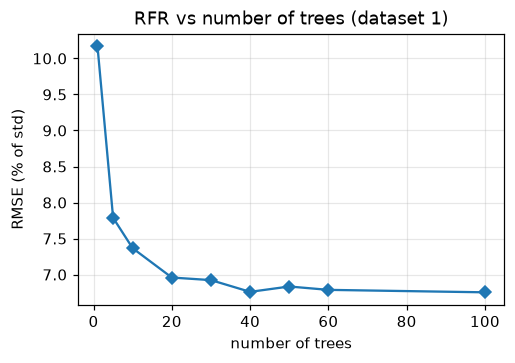

In [3]:
tr1, te1 = curve_split(ds1, 0.2)
trees = [1, 5, 10, 20, 30, 40, 50, 60, 100]
rmse = [regression_report(te.I_D, te.I_pred)["RMSE_%std"]
        for te in (fit_predict(tr1, te1, n_trees=n)[1] for n in trees)]
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(trees, rmse, "D-")
ax.set(xlabel="number of trees", ylabel="RMSE (% of std)", title="RFR vs number of trees (dataset 1)")
fig.savefig("../figures/02_trees.png", bbox_inches="tight")

## A3. Fig. 5 and 6: train/test curves and parity plots per parameter

### 📈 Block: do the guessed curves look right? (paper's Fig. 5 and 6)
**What it does:** trains the 50-tree forest on dataset 1, then for each knob picks one exam curve and draws:
* **top row:** the true curve (line) vs the forest's guesses (circles). Black/red use the left **log** axis; blue uses the
  right **linear** axis, just like the paper's figure.
* **bottom row:** a **parity plot**: each dot is one point, x = true current, y = guessed current. Perfect guesses sit
  exactly on the black diagonal line.

dataset 1 test: {'R2_linear_%': 99.533, 'RMSE_%std': np.float64(6.835), 'R2_log10_%': 63.951, 'median_rel_err_%': np.float64(6.351), 'p95_rel_err_%': np.float64(1459710.85)}


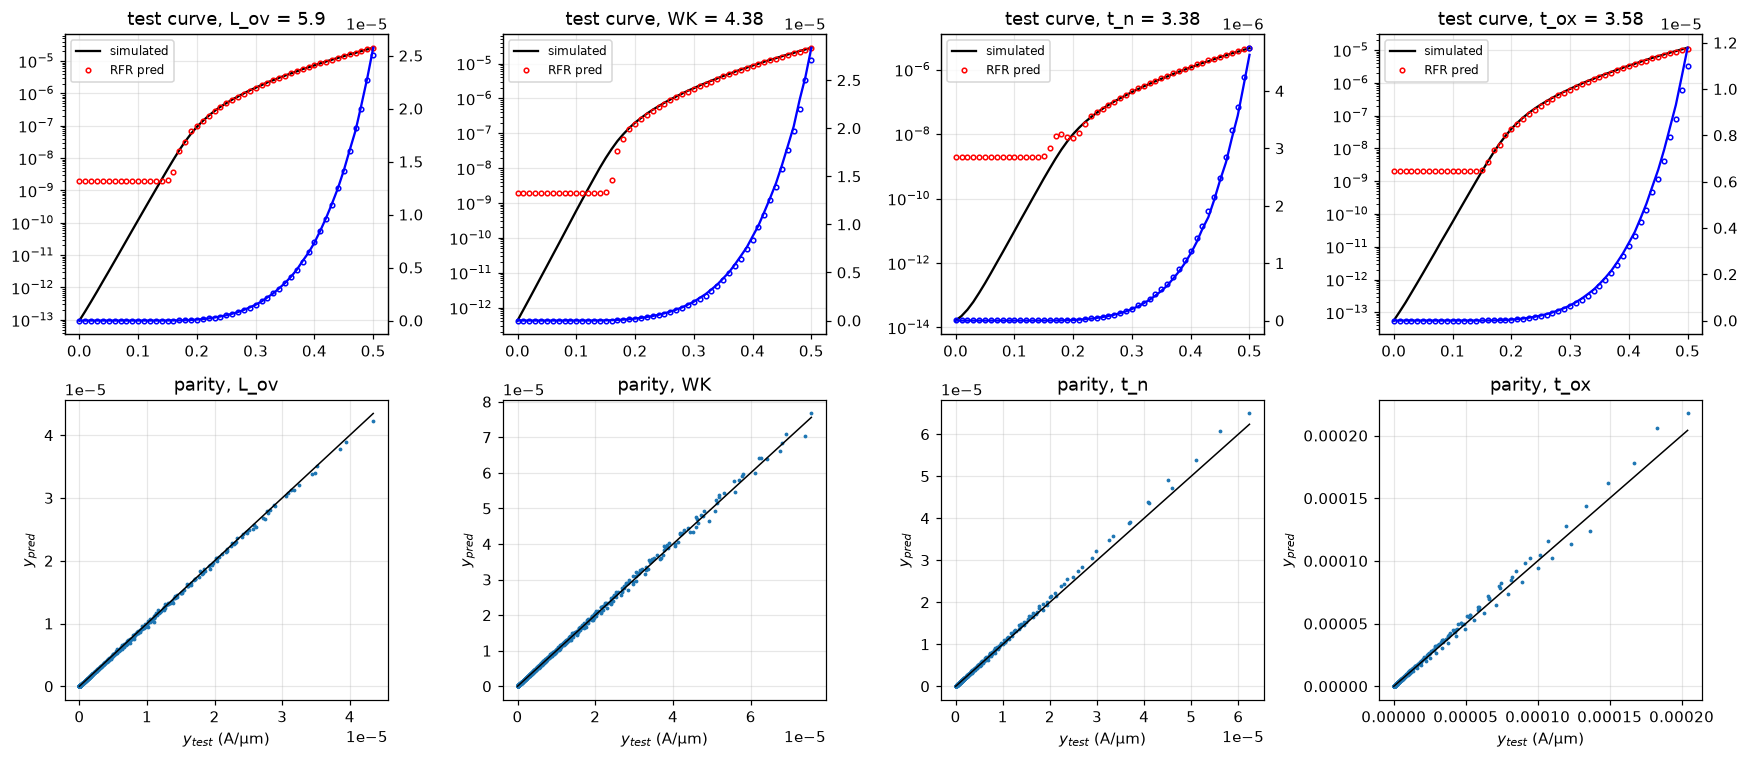

In [4]:
model1, te1 = fit_predict(tr1, te1)
print("dataset 1 test:", {k: round(v, 3) for k, v in regression_report(te1.I_D, te1.I_pred).items()})

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, name in enumerate(PARAM_RANGES):
    sub = te1[te1.varied == name]
    cid = sub.curve_id.unique()[len(sub.curve_id.unique()) // 2]
    c = sub[sub.curve_id == cid]
    ax = axes[0, j]                                  # log axis (left) + linear axis (right), as in Fig. 5
    ax.semilogy(c.V_G, c.I_D, "k-", label="simulated")
    ax.semilogy(c.V_G, c.I_pred, "ro", ms=3, mfc="none", label="RFR pred")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(c.V_G, c.I_D, "b-"); ax2.plot(c.V_G, c.I_pred, "bo", ms=3, mfc="none")
    ax.set_title(f"test curve, {name} = {c[name].iloc[0]:.3g}")
    ax.legend(fontsize=8)
    axes[1, j].plot(sub.I_D, sub.I_pred, ".", ms=3)
    lim = [0, sub.I_D.max()]; axes[1, j].plot(lim, lim, "k-", lw=1)
    axes[1, j].set(xlabel="$y_{test}$ (A/µm)", ylabel="$y_{pred}$", title=f"parity, {name}")
fig.tight_layout()
fig.savefig("../figures/02_fig5_fig6.png", bbox_inches="tight")

## A4. Datasets 2, 3, 4: joint $L_{ov}$–$t_n$ variation, drain bias, all parameters (Fig. 7–9)

For dataset 3, $V_D$ becomes a sixth input. For dataset 4, the paper used 100 trees.

### 📦 Block: harder datasets 2, 3 and 4 (paper's Fig. 7 to 9)
**What it does:** repeats "train on 80 %, test on 20 %" for:
* **ds2:** two knobs changing together, **ds3:** also the battery $V_D$ (so the model gets a 6th input),
* **ds4:** all four knobs random, the hardest and most realistic one (100 trees, like the paper).

It prints one row of scores per dataset. Columns ending in `log10` look at errors on the log scale (they also count the
tiny OFF currents fairly). `train_s` = seconds to train.

In [5]:
ds2 = pd.read_pickle("../data/ds2_lov_tn.pkl")
ds3 = pd.read_pickle("../data/ds3_drain_bias.pkl")
results = {}
for name, df, feats, n in (("ds2 L_ov+t_n", ds2, FEATURES, 50),
                           ("ds3 drain bias", ds3, FEATURES + ["V_D"], 50),
                           ("ds4 all params", ds4, FEATURES, 100)):
    tr, te = curve_split(df, 0.2)
    t0 = time.perf_counter()
    m, te = fit_predict(tr, te, feats, n)
    results[name] = {**regression_report(te.I_D, te.I_pred), "train_s": time.perf_counter() - t0}
    if name.startswith("ds3"): model3, te3 = m, te
    if name.startswith("ds4"): model4, te4 = m, te
pd.DataFrame(results).T.round(3)

,R2_linear_%,RMSE_%std,R2_log10_%,median_rel_err_%,p95_rel_err_%,train_s
ds2 L_ov+t_n,98.530,12.124,56.104,29.841,3.695685e+06,0.078
ds3 drain bias,76.148,48.838,46.139,204.698,1.313040e+07,0.261
ds4 all params,93.253,25.976,63.717,62.056,3.856364e+06,1.600


### 🖼️ Block: pictures for datasets 3 and 4
**What it does:** **left:** one exam switch at three battery strengths, true (lines) vs guessed (markers).
**right:** four random exam switches from ds4. Both plots use the linear axis, like the paper.

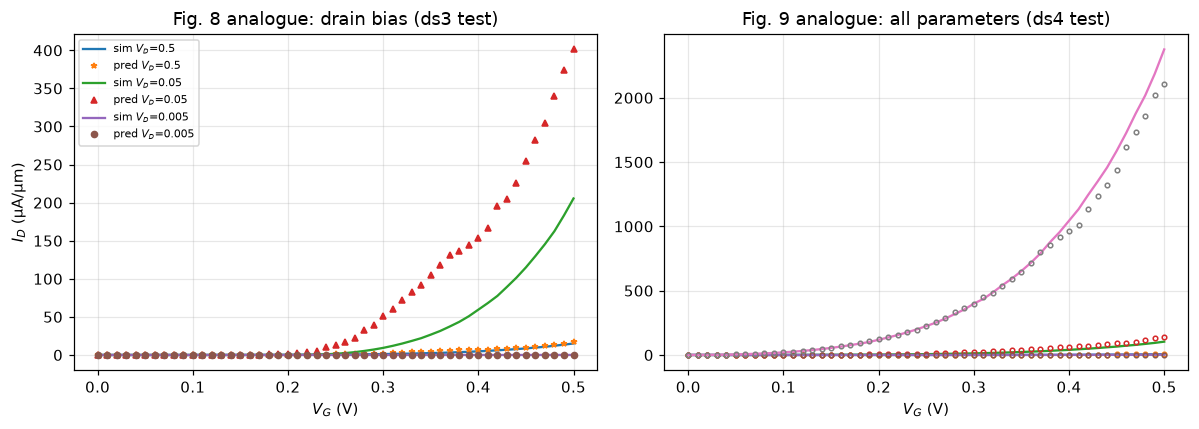

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
dev = te3.drop_duplicates("curve_id").iloc[0]
for vd, mk in ((0.5, "*"), (0.05, "^"), (0.005, "o")):
    c = te3[np.isclose(te3.V_D, vd)]
    cid = c.curve_id.unique()[0]; c = c[c.curve_id == cid]
    a.plot(c.V_G, c.I_D * 1e6, "-", label=f"sim $V_D$={vd}")
    a.plot(c.V_G, c.I_pred * 1e6, mk, ms=4, label=f"pred $V_D$={vd}")
a.set(title="Fig. 8 analogue: drain bias (ds3 test)", xlabel="$V_G$ (V)", ylabel="$I_D$ (µA/µm)"); a.legend(fontsize=7)
for cid in te4.curve_id.unique()[:4]:
    c = te4[te4.curve_id == cid]
    b.plot(c.V_G, c.I_D * 1e6, "-"); b.plot(c.V_G, c.I_pred * 1e6, "o", ms=3, mfc="none")
b.set(title="Fig. 9 analogue: all parameters (ds4 test)", xlabel="$V_G$ (V)")
fig.tight_layout(); fig.savefig("../figures/02_fig8_fig9.png", bbox_inches="tight")

## A5. Fig. 10 and Table 5: an unseen random device, and $SS_{min}$ from predicted curves

### 🎲 Block: a brand-new switch, plus the "snappiness" test (paper's Fig. 10 and Table 5)
**What it does:**
1. Builds the exact random switch from the paper's Fig. 10 (knob values the model never saw), simulates it, asks the forest
   to guess it, and plots guess vs truth.
2. For dataset 1, measures **$SS_{min}$** (how snappy the switch is) from the **true** curves and from the **guessed** curves,
   and compares the averages. If the guesser is good, the two columns should match.

,parameter,simulated SS_min,predicted SS_min
0,L_ov,31.20,29.72
1,WK,31.63,37.07
2,t_n,30.48,50.55
3,t_ox,31.54,40.11


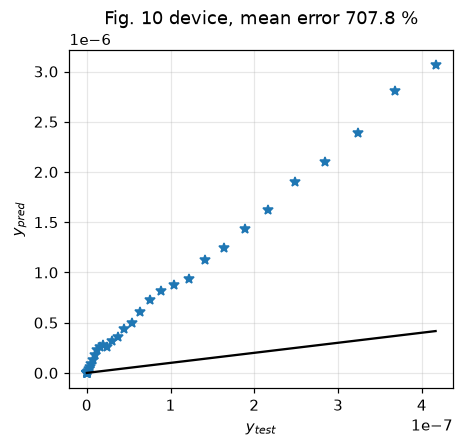

In [7]:
unknown = {"L_ov": 0.15, "t_ox": 3.04, "t_n": 2.04, "WK": 4.44}    # the paper's Fig. 10 device
V, I = id_vg(unknown)                         # true answer from the simulator
X = pd.DataFrame({"V_G": V, **unknown})[FEATURES]
I_hat = model4.predict(X)                     # the forest's guess
err = 100 * np.mean(np.abs(I_hat - I)) / np.mean(I)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(I, I_hat, "*", ms=7); ax.plot([0, I.max()], [0, I.max()], "k-")
ax.set(xlabel="$y_{test}$", ylabel="$y_{pred}$", title=f"Fig. 10 device, mean error {err:.1f} %")
fig.savefig("../figures/02_fig10.png", bbox_inches="tight")

ss = []
for name in PARAM_RANGES:
    sub = te1[te1.varied == name]
    t, p = fom_per_curve(sub, "I_D"), fom_per_curve(sub, "I_pred")
    ss.append({"parameter": name, "simulated SS_min": t.SS_min.mean(), "predicted SS_min": p.SS_min.mean()})
pd.DataFrame(ss).round(2)

**Part A conclusion:** on dataset 1 (one parameter at a time, the paper's main experiment) the baseline
reaches $R^2$ ≈ 99.5 % on linear current, close to the paper's 99.9 %. Two warning signs already show up:
$R^2$ drops on datasets 2–4, where parameters vary together, and the $SS_{min}$ extracted from predicted
curves is off by up to ~20 mV/dec for $t_n$ (Table 5 analogue above).

---
# Part B · Where the baseline breaks

## B1. Linear-scale $R^2$ hides the subthreshold region

$R^2$ on linear current is dominated by the few points near $I_{ON}$ (~1e-5 A/µm). A TFET's whole point is
what happens between 1e-14 and 1e-8 A/µm. Let's look at the error **per decade of current** on dataset 4.

### 🔍 Block: how wrong is it at each current level?
**What it does:** groups every exam point by how big its true current is (1e-15, 1e-14, … 1e-3 A/µm, one group per
"decade" = power of 10) and shows the **typical % mistake** in each group. The y-axis is log scale too.

**Why it matters:** $R^2$ on the normal scale mostly "sees" the big ON currents. If the bars on the left (tiny currents)
are huge, the model is bad exactly where a TFET is special, even with a high $R^2$.

dataset 4, paper metrics + log metrics:
{'R2_linear_%': 93.25, 'RMSE_%std': np.float64(25.98), 'R2_log10_%': 63.72, 'median_rel_err_%': np.float64(62.06), 'p95_rel_err_%': np.float64(3856363.67)}


,0,1,2,3,4,5,6,7,8,9,10,11,12
decade,-15.0,-14.0,-13.0,-12.0,-11.0,-10.0,-9.0,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0
median,13743942.8,5760580.5,424647.2,47459.2,6259.0,872.8,136.6,57.0,39.3,29.7,23.3,20.8,15.5
count,369.0,1335.0,893.0,1009.0,1193.0,1624.0,2400.0,3618.0,4760.0,4596.0,2900.0,771.0,32.0


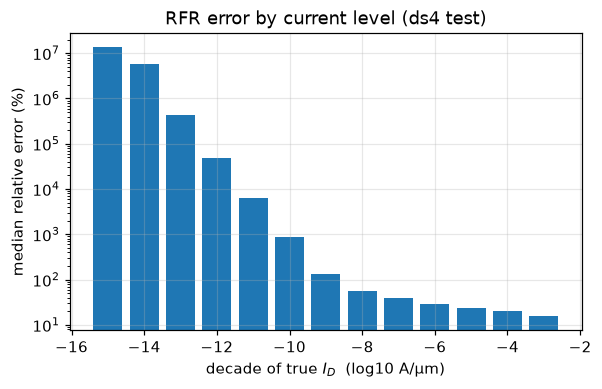

In [8]:
print("dataset 4, paper metrics + log metrics:")
print({k: round(v, 2) for k, v in regression_report(te4.I_D, te4.I_pred).items()})
dec = error_by_decade(te4.I_D, te4.I_pred)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dec.decade, dec["median"])
ax.set_yscale("log")
ax.set(xlabel="decade of true $I_D$  (log10 A/µm)", ylabel="median relative error (%)",
       title="RFR error by current level (ds4 test)")
fig.savefig("../figures/02_error_by_decade.png", bbox_inches="tight")
dec.round(1).T

## B2. What a device engineer actually needs: figures of merit

Extract $I_{ON}, I_{OFF}, V_{th}, SS_{min}$ from each predicted test curve and compare with the simulator.
`*_missing_%` = share of test curves where the FoM exists in the simulated curve but **cannot be extracted**
from the predicted one.

### 📝 Block: report-card scores from guessed curves
**What it does:** for every exam switch, computes the report-card numbers ($I_{ON}$, $I_{OFF}$, $V_{th}$, $SS_{min}$) twice,
from the true curve and from the guessed curve, and shows the average difference:
* `I_on_err_%`: ON current mistake in % · `I_off_err_decades`: OFF current mistake in powers of 10 (1 = 10× off!)
* `V_th_err_mV`, `SS_min_err_mV/dec`: mistakes in threshold and snappiness
* `*_missing_%`: how often the score **can't even be calculated** from the guessed curve (`NaN` = never possible)

It also prints the smallest current the forest ever guesses, compared with the smallest true current.

In [9]:
print("lowest current the RFR ever predicts on ds4 test:", f"{te4.I_pred.min():.2e} A/um",
      "| lowest true current:", f"{te4.I_D.min():.2e} A/um")
pd.Series(fom_errors(te4)).round(2).to_frame("RFR (paper) on ds4 test")

lowest current the RFR ever predicts on ds4 test: 1.09e-09 A/um | lowest true current: 5.10e-15 A/um


,RFR (paper) on ds4 test
I_on_err_%,64.67
I_off_err_decades,3.34
V_th_err_mV,NaN
V_th_missing_%,77.40
SS_min_err_mV/dec,20.20
SS_min_missing_%,6.60


The linear-target forest averages leaf values in linear space, so leaves that mix on- and off-state points are
dominated by the large currents. **Its predictions never fall below ~1e-9 A/µm**: the whole off-state is lost,
$I_{OFF}$ is wrong by several decades, and a constant-current $V_{th}$ ($10^{-10}$ A/µm) can't be extracted
from any predicted curve.

## B3. A random forest is a staircase

Trees are piecewise-constant in every input. Evaluate the trained model on a fine $V_G$ grid (501 points), then
take the derivative, as you would for $g_m$ or point-wise SS.

### 🪜 Block: the staircase problem
**What it does:** asks the forest to guess the default switch at **501** closely spaced $V_G$ points (instead of 51) and draws:
* **left:** the curve. A tree's answer only changes when it crosses one of its yes/no thresholds, so the guess comes out in
  **flat steps**, like a staircase, instead of a smooth curve;
* **right:** the **slope** of the curve ($g_m$, transconductance), which circuit designers need. The slope of a staircase
  is zero on each step and a spike at each edge, which is useless.

It also prints the % of exam curves where the guessed current goes **down** while $V_G$ goes up. That's physically wrong
for this device.

curves with a non-monotonic prediction (ds4 test): 24.2 %


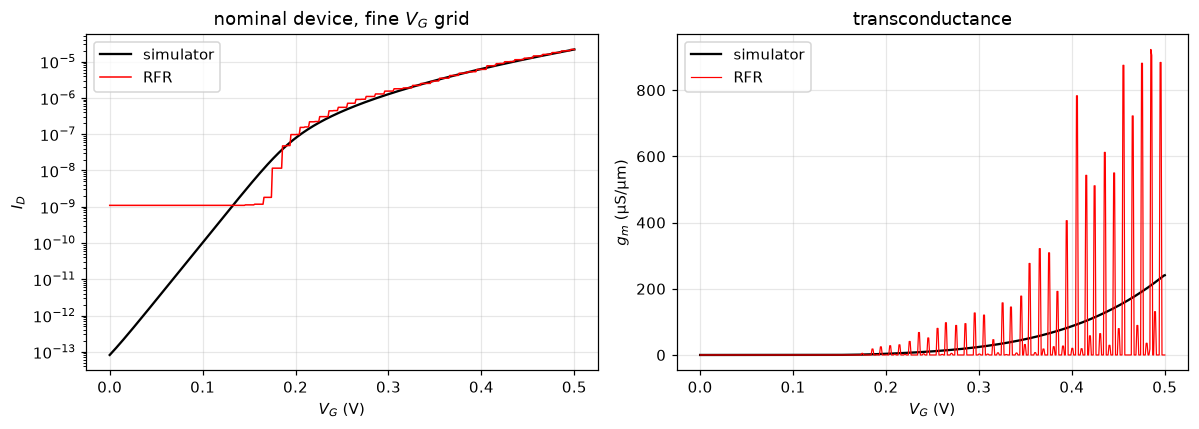

In [10]:
Vf = np.linspace(0, 0.5, 501)
_, If = id_vg(NOMINAL, V_G=Vf)
Xf = pd.DataFrame({"V_G": Vf, **NOMINAL})[FEATURES]
If_hat = model4.predict(Xf)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.semilogy(Vf, If, "k-", label="simulator"); a.semilogy(Vf, If_hat, "r-", lw=1, label="RFR")
a.set(xlabel="$V_G$ (V)", ylabel="$I_D$", title="nominal device, fine $V_G$ grid"); a.legend()
b.plot(Vf, np.gradient(If, Vf) * 1e6, "k-", label="simulator")
b.plot(Vf, np.gradient(If_hat, Vf) * 1e6, "r-", lw=0.8, label="RFR")
b.set(xlabel="$V_G$ (V)", ylabel="$g_m$ (µS/µm)", title="transconductance"); b.legend()
fig.tight_layout(); fig.savefig("../figures/02_staircase.png", bbox_inches="tight")
print(f"curves with a non-monotonic prediction (ds4 test): {monotonic_violations(te4):.1f} %")

## B4. No extrapolation

Train only on devices with $t_{ox}$ ≥ 2 nm and test on thinner oxides (1–2 nm). That's a realistic "next
technology node" question.

### 🚀 Block: can it predict something new? (extrapolation)
**What it does:** trains **only** on switches with thick oxide ($t_{ox}$ ≥ 2 nm), then asks about thinner oxides (1–2 nm).
Engineers ask this kind of question all the time: "what if we make it a bit smaller than anything we've built?"

The plot shows true vs guessed ON current. Dots on the diagonal = right; dots stuck in a flat line = the model just repeats
the largest values it has seen (trees can't guess beyond their training examples).

extrapolation to t_ox < 2 nm: {'R2_linear_%': 37.32, 'RMSE_%std': np.float64(79.17), 'R2_log10_%': 73.52, 'median_rel_err_%': np.float64(74.68), 'p95_rel_err_%': np.float64(455638.85)}


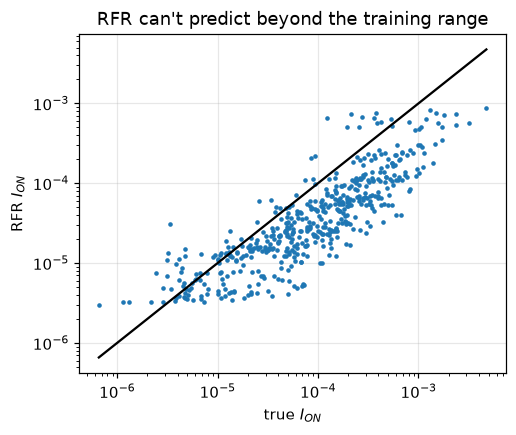

In [11]:
inside = ds4[ds4.t_ox >= 2.0]; outside = ds4[ds4.t_ox < 2.0]   # learn on thick, test on thin
mx, out = fit_predict(inside, outside, n_trees=100)
print("extrapolation to t_ox < 2 nm:", {k: round(v, 2) for k, v in regression_report(out.I_D, out.I_pred).items()})
fig, ax = plt.subplots(figsize=(5, 4))
fo_t, fo_p = fom_per_curve(out, "I_D"), fom_per_curve(out, "I_pred")
ax.loglog(fo_t.I_on, fo_p.I_on, ".", ms=4); lim = [fo_t.I_on.min(), fo_t.I_on.max()]
ax.plot(lim, lim, "k-")
ax.set(xlabel="true $I_{ON}$", ylabel="RFR $I_{ON}$", title="RFR can't predict beyond the training range")
fig.savefig("../figures/02_extrapolation.png", bbox_inches="tight")

## B5. How many simulations does it need?

The paper used 2500 TCAD runs (≈ 125 h at their 5 h / 100 curves). How does accuracy depend on that number?
(We use log-space metrics here; linear $R^2$ jumps around because a handful of very high-current devices dominate it.)

### 📉 Block: how many examples does it need? (learning curve)
**What it does:** keeps one fixed exam set, then trains forests on only 25, 50, 100 … 1600 example curves and scores each.
In the paper each simulated curve costs ~3 minutes of slow TCAD, so **needing fewer examples = saving days of compute**.
The table is saved to `data/learning_curve_rfr.csv` so notebook 4 can compare against it.

In [12]:
_, te_fix = curve_split(ds4, 0.2, seed=7)
pool = ds4[~ds4.curve_id.isin(te_fix.curve_id)]
rows = []
for n in (25, 50, 100, 200, 400, 800, 1600):
    ids = np.random.default_rng(0).choice(pool.curve_id.unique(), n, replace=False)
    _, te = fit_predict(pool[pool.curve_id.isin(ids)], te_fix, n_trees=100)
    r = regression_report(te.I_D, te.I_pred)
    rows.append({"train curves": n, "R2_log10_%": r["R2_log10_%"], "median_rel_err_%": r["median_rel_err_%"]})
lc_rf = pd.DataFrame(rows)
lc_rf.to_csv("../data/learning_curve_rfr.csv", index=False)
lc_rf.round(2)

,train curves,R2_log10_%,median_rel_err_%
0,25,43.82,450.92
1,50,42.31,355.25
2,100,51.47,245.68
3,200,54.16,207.67
4,400,56.12,126.80
5,800,59.87,110.64
6,1600,62.03,76.81


## Summary: gaps this project addresses

**🧒 In simple words:** the paper's guesser gets a great-looking score because it's graded mostly on the *big* currents.
When we check the *tiny* OFF currents, the "snappiness" (SS), smooth curves and new designs, it does badly.
The next notebooks build a better guesser and fix each problem in this table:

| Gap in the paper | Evidence above | Fix | Notebook |
|---|---|---|---|
| Linear-scale target and metrics hide subthreshold errors | B1, B2 | log10 target, region-wise + FoM metrics | 03 |
| Piecewise-constant model: noisy $g_m$/SS, non-monotonic curves | B3 | smooth physics-informed NN with monotonicity loss | 03 |
| No extrapolation | B4 | physics features ($\lambda$, $A_{tun}$) + smooth NN | 03 |
| No confidence estimate | n/a | deep ensembles | 04 |
| Needs thousands of expensive simulations | B5 | active learning | 04 |
| Temperature / PVT missing (paper's future work) | n/a | extended dataset with $V_D$ and $T$ | 04 |
| Only forward prediction | n/a | SHAP explainability + multi-objective inverse design | 05 |